# Chapitre 4 - Cours 1 : compatibilité, formats propres au langage, JSON et ses variantes binaires

Une application change sans cesse, mais ses données lui survivent et circulent entre des
processus qui n'ont pas tous la même version du code. Ce premier cours pose le problème
(compatibilité dans les deux sens) puis passe en revue les formats d'encodage « sans
schéma imposé » : sérialisation native du langage, formats textuels (JSON, XML, CSV) et
leurs variantes binaires. Il couvre l'introduction du chapitre et la section *Formats for
Encoding Data* jusqu'à la sous-section *Binary encoding*.

**Plan.**

1. Le code change, les données restent : compatibilités descendante et ascendante.
2. Deux représentations des données : en mémoire et en octets.
3. Les formats propres au langage, et pourquoi s'en méfier.
4. JSON, XML et CSV : lisibles, universels, mais flous.
5. Les variantes binaires de JSON : un encodeur MessagePack écrit à la main.


In [1]:
import base64
import csv
import io
import json
import pickle
import sys
import xml.etree.ElementTree as ET
from dataclasses import dataclass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 80)
rng = np.random.default_rng(0)
R = E.EXAMPLE_RECORD

## 1. Le code change, les données restent (introduction du chapitre)

Au chapitre 1, l'**évolutivité** désignait la facilité à faire changer un
système. Presque toute évolution fonctionnelle touche aux données : un nouveau champ, un
nouveau type d'enregistrement, une autre façon de présenter l'existant. Les modèles de
données du chapitre 2 réagissent différemment : une base relationnelle
impose **un** schéma à tout instant (que l'on change par migration, `ALTER TABLE`), une
base « sans schéma » (schéma à la lecture) laisse cohabiter des enregistrements écrits à
des époques différentes, dans des formats différents.

Le vrai problème est ailleurs : dans une grosse application, **le code ne change pas
partout au même instant**.

- Côté serveur, on fait un **déploiement progressif** (rolling upgrade) : la nouvelle
  version est installée sur quelques nœuds, on surveille, puis on continue. Pas
  d'interruption de service, donc des déploiements plus fréquents.
- Côté client (application mobile, logiciel installé), c'est l'utilisateur qui décide
  quand mettre à jour, parfois jamais.

Ancien et nouveau code, anciennes et nouvelles données **coexistent** donc. Il faut deux
propriétés :

| Propriété | Anglais | Signification |
|---|---|---|
| **compatibilité descendante** | backward compatibility | le **nouveau** code sait lire les données écrites par l'**ancien** |
| **compatibilité ascendante** | forward compatibility | l'**ancien** code sait lire les données écrites par le **nouveau** |

Moyen mnémotechnique : on se place du point de vue du code qui lit. « Backward » : il
regarde en arrière (des données plus vieilles que lui) ; « forward » : il regarde vers
l'avant (des données venues du futur).

Simulons un déploiement progressif sur 12 nœuds, un nœud toutes les 10 minutes, et
comptons les couples (écrivain, lecteur) possibles quand un nœud lit ce qu'un autre a
écrit.

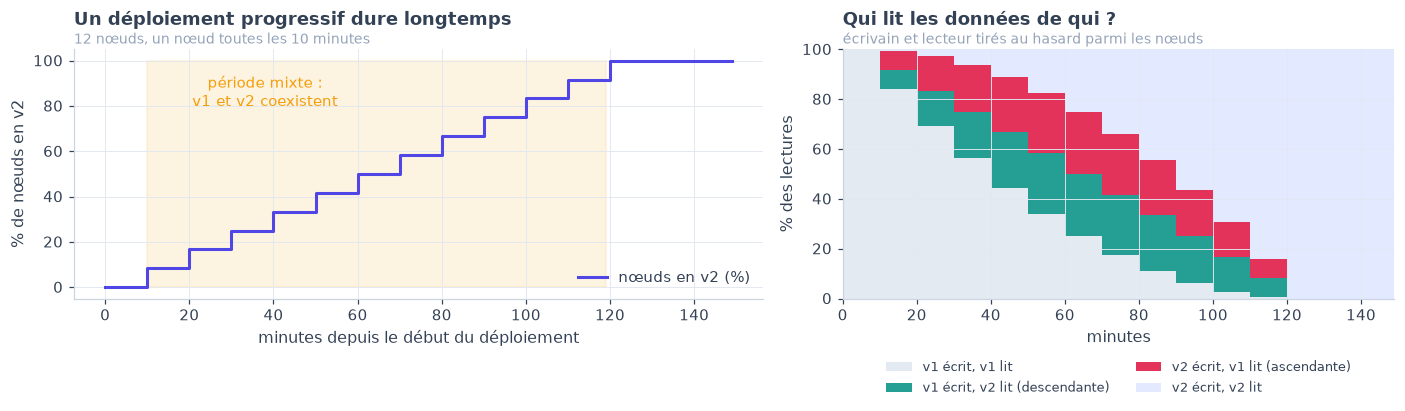

In [2]:
n_nodes, step = 12, 10                     # un nœud mis à jour toutes les 10 minutes
t = np.arange(0, 150)
v2 = np.clip((t - 10) // step + 1, 0, n_nodes) / n_nodes
v2[t < 10] = 0
combos = {                                 # (écrivain, lecteur) tirés au hasard parmi les nœuds
    "v1 écrit, v1 lit": (1 - v2) ** 2,
    "v1 écrit, v2 lit (descendante)": (1 - v2) * v2,
    "v2 écrit, v1 lit (ascendante)": v2 * (1 - v2),
    "v2 écrit, v2 lit": v2 ** 2,
}

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax.step(t, v2 * 100, where="post", color=INDIGO, label="nœuds en v2 (%)")
ax.fill_between(t, 0, 100, where=(v2 > 0) & (v2 < 1), step="post", color=AMBER, alpha=0.12)
ax.text(38, 80, "période mixte :\nv1 et v2 coexistent", ha="center", color=AMBER, fontsize=10)
ax.set_xlabel("minutes depuis le début du déploiement"); ax.set_ylabel("% de nœuds en v2")
ax.set_title("Un déploiement progressif dure longtemps")
subtitle(ax, "12 nœuds, un nœud toutes les 10 minutes")
ax.legend(loc="lower right")

ax2.stackplot(t, *[100 * c for c in combos.values()], labels=list(combos), step="post",
              colors=[LIGHT[SLATE], TEAL, ROSE, LIGHT[INDIGO]], alpha=0.9)
ax2.set_xlabel("minutes"); ax2.set_ylabel("% des lectures")
ax2.set_title("Qui lit les données de qui ?")
subtitle(ax2, "écrivain et lecteur tirés au hasard parmi les nœuds")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)
ax2.set_xlim(0, 149); ax2.set_ylim(0, 100)
plt.tight_layout(); plt.show()

À mi-parcours, la moitié des lectures croisent les versions : un quart dans chaque
sens. Et ce n'est que la partie visible : une donnée écrite en base par v1 peut être lue
par v2 des années plus tard (la compatibilité descendante sert alors en permanence).

La compatibilité descendante est en général facile : l'auteur du nouveau code connaît
l'ancien format et peut le traiter explicitement. L'ascendante est plus délicate,
puisque l'ancien code doit **ignorer** proprement des ajouts qu'il ne pouvait pas
prévoir. Un piège classique, illustré ci-dessous : v2 ajoute un champ, v1 relit
l'enregistrement dans un objet de son modèle (qui n'a pas ce champ), le modifie et le
réécrit. Le champ ajouté disparaît sans bruit.



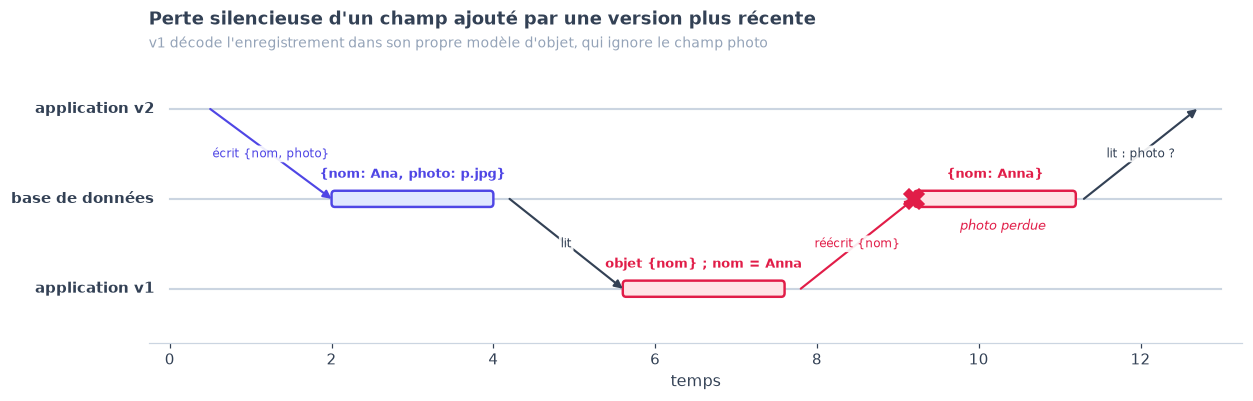

In [3]:
st = SpaceTime(["application v2", "base de données", "application v1"], t_max=13, width=11.5,
               title="Perte silencieuse d'un champ ajouté par une version plus récente",
               subtitle="v1 décode l'enregistrement dans son propre modèle d'objet, qui ignore le champ photo")
st.msg("application v2", 0.5, "base de données", 2.0, "écrit {nom, photo}", color=INDIGO)
st.op("base de données", 2.0, 4.0, "{nom: Ana, photo: p.jpg}", color=INDIGO)
st.msg("base de données", 4.2, "application v1", 5.6, "lit", color=SLATE)
st.op("application v1", 5.6, 7.6, "objet {nom} ; nom = Anna", color=ROSE)
st.msg("application v1", 7.8, "base de données", 9.2, "réécrit {nom}", color=ROSE)
st.op("base de données", 9.2, 11.2, "{nom: Anna}", color=ROSE)
st.msg("base de données", 11.3, "application v2", 12.7, "lit : photo ?", color=SLATE)
st.event("base de données", 9.2, kind="crash")
st.note(10.3, "base de données", "photo perdue", dy=-0.3, color=ROSE)
st.show()

> **À retenir.** Pendant un déploiement progressif, et pour toutes les données stockées,
> plusieurs versions du code et du format coexistent. Il faut la **compatibilité
> descendante** (le nouveau code lit l'ancien format) et la **compatibilité ascendante**
> (l'ancien code lit le nouveau format, en ignorant et si possible en préservant ce qu'il
> ne connaît pas).

## 2. Deux représentations des données (section *Formats for Encoding Data*)

Un programme manipule ses données sous (au moins) deux formes :

- **en mémoire** : objets, structures, listes, tables de hachage, arbres, optimisés pour
  le processeur et truffés de **pointeurs** (adresses mémoire) ;
- **en octets** : pour écrire dans un fichier ou envoyer sur le réseau, il faut une
  séquence d'octets autonome. Une adresse mémoire n'aurait aucun sens dans un autre
  processus.

Passer de la mémoire aux octets s'appelle **encoder** (sérialiser, « marshaling ») ;
l'inverse, **décoder** (désérialiser, analyser, « parsing »). Le livre préfère le mot
*encodage*, car « sérialisation » désigne tout autre chose dans le contexte des
transactions (chapitre 7).

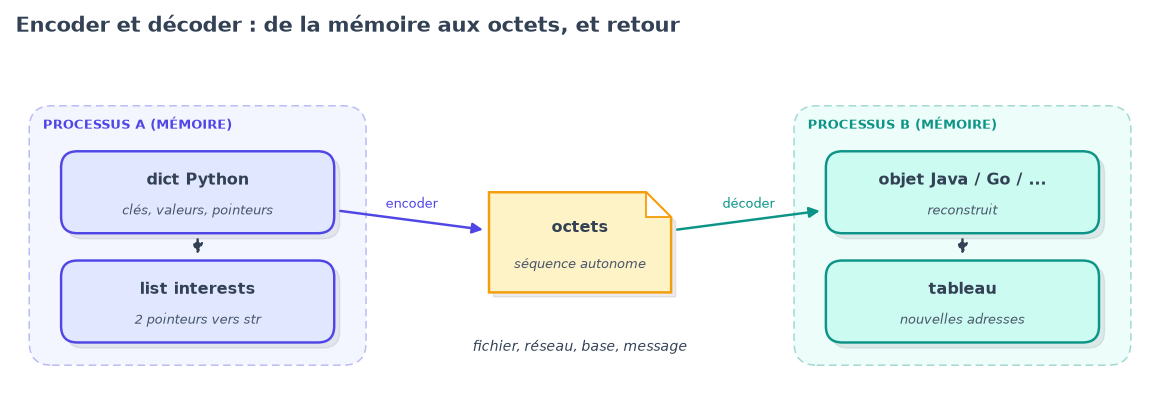

In [4]:
d = Diagram(12.5, 3.6, title="Encoder et décoder : de la mémoire aux octets, et retour")
d.group(0.2, 0.25, 3.9, 3.1, "processus A (mémoire)", color=INDIGO)
d.box("objA", 2.05, 2.15, "dict Python", sub="clés, valeurs, pointeurs", color=INDIGO, w=3.0)
d.box("lstA", 2.05, 0.95, "list interests", sub="2 pointeurs vers str", color=INDIGO, w=3.0)
d.arrow("objA", "lstA", style="dotted")
d.box("bytes", 6.25, 1.6, "octets", sub="séquence autonome", color=AMBER, w=2.0, kind="doc", h=1.1)
d.group(8.6, 0.25, 12.3, 3.1, "processus B (mémoire)", color=TEAL)
d.box("objB", 10.45, 2.15, "objet Java / Go / ...", sub="reconstruit", color=TEAL, w=3.0)
d.box("lstB", 10.45, 0.95, "tableau", sub="nouvelles adresses", color=TEAL, w=3.0)
d.arrow("objB", "lstB", style="dotted")
d.arrow("objA", "bytes", "encoder", color=INDIGO)
d.arrow("bytes", "objB", "décoder", color=TEAL)
d.note(6.25, 0.45, "fichier, réseau, base, message", color=SLATE)
d.show()

Mesurons l'écart entre les deux représentations pour l'enregistrement d'exemple du
chapitre : la taille mémoire d'un `dict` Python (en suivant les pointeurs) et celle de
son encodage JSON compact. Les adresses (`id`) montrent pourquoi on ne peut pas
simplement « copier la mémoire » vers un autre processus.

In [5]:
def deep_size(o, seen=None):
    """Taille mémoire en octets, en suivant les références (dict, list, str, int)."""
    seen = set() if seen is None else seen
    if id(o) in seen:
        return 0
    seen.add(id(o))
    s = sys.getsizeof(o)
    if isinstance(o, dict):
        s += sum(deep_size(k, seen) + deep_size(v, seen) for k, v in o.items())
    elif isinstance(o, (list, tuple)):
        s += sum(deep_size(x, seen) for x in o)
    return s

print(json.dumps(R, ensure_ascii=False))
print(f"mémoire Python (objets suivis) : {deep_size(R)} octets ; JSON compact : {len(E.json_bytes(R))} octets")
print("adresses des objets en mémoire :", {k: hex(id(v)) for k, v in R.items()})

{"userName": "Martin", "favoriteNumber": 1337, "interests": ["daydreaming", "hacking"]}
mémoire Python (objets suivis) : 585 octets ; JSON compact : 81 octets
adresses des objets en mémoire : {'userName': '0x7a15e073af70', 'favoriteNumber': '0x7a15e093d1f0', 'interests': '0x7a15e0776080'}


Le `dict` occupe environ sept fois plus de place en mémoire que son JSON : en-têtes
d'objets, compteurs de références, tables de hachage à moitié vides, pointeurs. Ces
structures sont faites pour un accès rapide, pas pour être compactes ni transportables.


> **À retenir.** Encoder = transformer des structures en mémoire (pleines de pointeurs)
> en une séquence d'octets autonome ; décoder = l'inverse. Tout échange de données entre
> processus qui ne partagent pas de mémoire passe par là.

## 3. Les formats propres au langage (section *Language-Specific Formats*)

Beaucoup de langages savent encoder leurs objets nativement : `java.io.Serializable` en
Java, `Marshal` en Ruby, `pickle` en Python. C'est commode (une ligne de code), mais le
livre relève quatre problèmes profonds. Vérifions-les un par un avec `pickle`.

**Problème 1 : le format est lié au langage.** Regardons les octets produits pour un
objet d'une classe applicative : on y lit le nom du module et de la classe Python.

In [6]:
@dataclass
class Person:
    userName: str
    favoriteNumber: int
    interests: list

blob = pickle.dumps(Person(**R))
print(len(blob), "octets")
print(blob[:60])

122 octets
b'\x80\x04\x95o\x00\x00\x00\x00\x00\x00\x00\x8c\x08__main__\x94\x8c\x06Person\x94\x93\x94)\x81\x94}\x94(\x8c\x08userName\x94\x8c\x06Martin\x94\x8c'


Pour relire ces octets, un programme Java ou Go devrait réimplémenter la machine à pile
de `pickle` et connaître la classe `__main__.Person`. Stocker ou transmettre des données
ainsi, c'est s'enchaîner à son langage pour longtemps et fermer la porte à l'intégration
avec d'autres équipes ou organisations.

**Problème 2 : la sécurité.** Pour reconstruire des objets de n'importe quel type, le
décodeur doit pouvoir instancier des classes arbitraires, donc appeler du code
arbitraire. Un attaquant qui fait décoder ses octets à une application peut lui faire
exécuter ce qu'il veut. Démonstration inoffensive : un objet dont la méthode
`__reduce__` demande d'appeler `print` au décodage.

In [7]:
class Piege:
    def __reduce__(self):
        # au décodage, pickle appellera print(...) : ce pourrait être os.system(...)
        return (print, ("!!! code arbitraire exécuté pendant le décodage !!!",))

octets_malveillants = pickle.dumps(Piege())
resultat = pickle.loads(octets_malveillants)    # le simple fait de décoder exécute l'appel

!!! code arbitraire exécuté pendant le décodage !!!


Le décodage a exécuté un appel de fonction choisi par l'auteur des octets. C'est une
classe entière de vulnérabilités (désérialisation de données non fiables) qui a touché
de nombreux serveurs Java et applications Rails. La documentation de `pickle` le dit en
toutes lettres : ne jamais décoder des données d'origine non fiable.

**Problème 3 : la gestion des versions est une réflexion après coup.** Que se passe-t-il
si la classe change entre l'écriture et la lecture ? Simulons deux évolutions banales :
un champ ajouté à la classe, et une classe renommée.

In [8]:
class PersonV1:
    def __init__(self, name):
        self.name = name

old_blob = pickle.dumps(PersonV1("Ana"))

class PersonV1:                      # « v2 » de la même classe : un champ ajouté
    def __init__(self, name, email="?"):
        self.name, self.email = name, email
    def greet(self):
        return f"{self.name} <{self.email}>"

lu = pickle.loads(old_blob)          # pickle ne rappelle pas __init__ : pas de valeur par défaut
try:
    lu.greet()
except AttributeError as exc:
    print("champ ajouté   ->", type(exc).__name__, ":", exc)

del PersonV1                         # la classe est renommée ou déplacée dans un autre module
try:
    pickle.loads(old_blob)
except AttributeError as exc:
    print("classe renommée ->", type(exc).__name__, ":", exc)

champ ajouté   -> AttributeError : 'PersonV1' object has no attribute 'email'
classe renommée -> AttributeError : Can't get attribute 'PersonV1' on <module '__main__'>


Ni l'un ni l'autre cas n'est géré : le premier échoue tard (au premier usage du champ),
le second échoue au décodage. La compatibilité dans les deux sens est laissée au
programmeur.

**Problème 4 : l'efficacité est elle aussi secondaire.** Comparons les tailles.

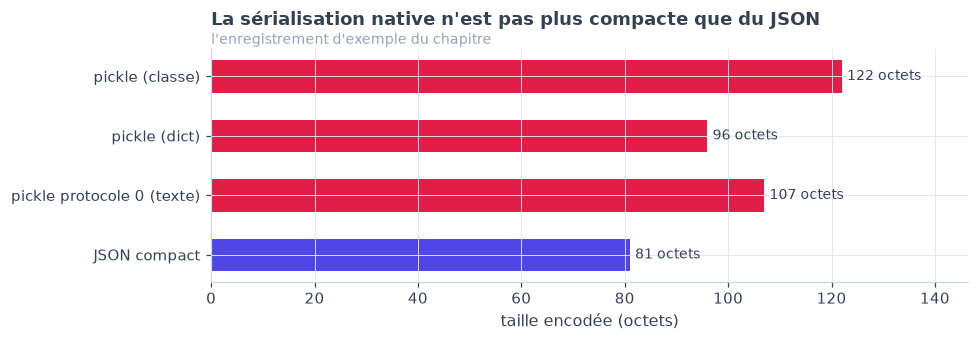

In [9]:
sizes = {
    "pickle (classe)": len(pickle.dumps(Person(**R))),
    "pickle (dict)": len(pickle.dumps(R)),
    "pickle protocole 0 (texte)": len(pickle.dumps(R, protocol=0)),
    "JSON compact": len(E.json_bytes(R)),
}
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(list(sizes), list(sizes.values()), color=[ROSE, ROSE, ROSE, INDIGO], height=0.55)
for i, v in enumerate(sizes.values()):
    ax.text(v + 1, i, f"{v} octets", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("taille encodée (octets)"); ax.set_xlim(0, max(sizes.values()) * 1.2)
ax.set_title("La sérialisation native n'est pas plus compacte que du JSON")
subtitle(ax, "l'enregistrement d'exemple du chapitre")
plt.tight_layout(); plt.show()

`pickle` fait ici un peu plus gros que le JSON compact (et la sérialisation native de
Java est réputée bien pire). D'où la recommandation du livre : réserver ces formats à des
usages très éphémères (un cache local, la communication entre processus d'une même
version), jamais au stockage durable ni aux échanges.

> **À retenir.** Les formats natifs (`pickle`, `Serializable`, `Marshal`) sont commodes
> mais liés au langage, dangereux sur des données non fiables, ignorants des versions et
> peu compacts : à éviter pour tout ce qui dure ou traverse une frontière.